<a href="https://colab.research.google.com/github/AdrianKazi/LeVJEPA-SigReg-Demo/blob/main/LeVJEPA_SigReg_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abstract

* LeVJEPA (LeVJ) is the first video encoder trained under LeJEPA's collapse-free objective, significantly reducing the complexity and computational cost of video representation learning.
* A single encoder is trained with an **invariance loss** over global and local views of a clip, regularized by **SIGReg**, which prevents representation collapse with a theoretical guarantee.
* Trainable architecture consists of an **encoder and a projector**, and the training objective requires only **one main loss hyperparameter**.
* Uniform random **token dropping** reduces the number of tokens processed by the encoder, significantly decreasing pretraining cost while surprisingly improving downstream accuracy.
* At a matched training setup, LeVJ matches or **outperforms V-JEPA 2** across ViT-S/B/L with **5.6–20.8× less total pretraining compute**. At matched total FLOPs, it exceeds the strongest video baseline by **7.6 percentage points on ImageNet-1K**, while remaining competitive on motion-centric benchmarks.
* LeVJEPA supports **block-causal attention**, meaning each frame's representation depends only on current and past observations, enabling chronological processing of video without access to future frames.
* **Appearance-centric accuracy:** LeVJ achieves results competitive with DINOv2, demonstrating strong visual representation learning.
* **Motion-centric accuracy:** LeVJ achieves almost **2× higher accuracy than DINOv2** trained on frames from the same videos under a comparable compute budget.

# Theoretical Minimum

## Toy Dataset

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

N, SIZE, RADIUS = 100, 64, 5
frames = np.zeros((N, SIZE, SIZE), dtype=np.float32)

yy, xx = np.ogrid[:SIZE, :SIZE]

for t in range(N):
    x = 8 + 48 * t / (N - 1)
    y = 32 + 15 * np.sin(2 * np.pi * t / N)
    frames[t] = ((xx - x)**2 + (yy - y)**2 <= RADIUS**2)

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
ax.axis("off")

def update(t):
    im.set_data(frames[t])
    return (im,)

anim = FuncAnimation(fig, update, frames=N, interval=40, blit=True)
plt.close(fig)
display(HTML(anim.to_jshtml()))

In [6]:
frames.shape

(100, 64, 64)

We have 100 time-frames, each of 64x64 pixels.

## Math

### Vectors and Embeddings

* **Vector** — A list of numbers, e.g. ball position `[x, y]`.
* **Embedding** — A vector produced by a neural network to represent input data.
* **Encoder** — Converts input data (image/video) into an embedding.

Example:
* Video → Encoder → `[0.2, -0.7, 1.4]`
* Similar videos → similar embeddings.

In [7]:
import torch
import torch.nn as nn

# Frames -> Vectors
x = torch.tensor(frames).flatten(1)  # [100, 4096]

# Minimal encoder
encoder = nn.Linear(4096, 2)
optimizer = torch.optim.Adam(encoder.parameters(), lr=1e-2)

# Store embeddings from each iteration
embeddings = []

N = 20

for i in range(N):
    z = encoder(x)
    embeddings.append(z.detach().clone())

    # Invariance loss between consecutive frames
    loss = ((z[1:] - z[:-1]) ** 2).mean()

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print(f"Iteration {i+1:}/{N} | Loss: {loss.item():.6f} | Mean: {z.mean().item():.4f}")

print(f"Final shape: {torch.stack(embeddings).shape}")

Iteration 1/20 | Loss: 0.001501 | Mean: -0.0135
Iteration 2/20 | Loss: 0.007281 | Mean: -0.0067
Iteration 3/20 | Loss: 0.001840 | Mean: 0.0085
Iteration 4/20 | Loss: 0.001729 | Mean: 0.0155
Iteration 5/20 | Loss: 0.003209 | Mean: 0.0121
Iteration 6/20 | Loss: 0.002503 | Mean: 0.0073
Iteration 7/20 | Loss: 0.001088 | Mean: 0.0067
Iteration 8/20 | Loss: 0.000767 | Mean: 0.0094
Iteration 9/20 | Loss: 0.001348 | Mean: 0.0130
Iteration 10/20 | Loss: 0.001602 | Mean: 0.0150
Iteration 11/20 | Loss: 0.001158 | Mean: 0.0136
Iteration 12/20 | Loss: 0.000617 | Mean: 0.0099
Iteration 13/20 | Loss: 0.000519 | Mean: 0.0061
Iteration 14/20 | Loss: 0.000740 | Mean: 0.0039
Iteration 15/20 | Loss: 0.000834 | Mean: 0.0040
Iteration 16/20 | Loss: 0.000654 | Mean: 0.0062
Iteration 17/20 | Loss: 0.000416 | Mean: 0.0099
Iteration 18/20 | Loss: 0.000341 | Mean: 0.0138
Iteration 19/20 | Loss: 0.000413 | Mean: 0.0161
Iteration 20/20 | Loss: 0.000461 | Mean: 0.0158
Final shape: torch.Size([20, 100, 2])


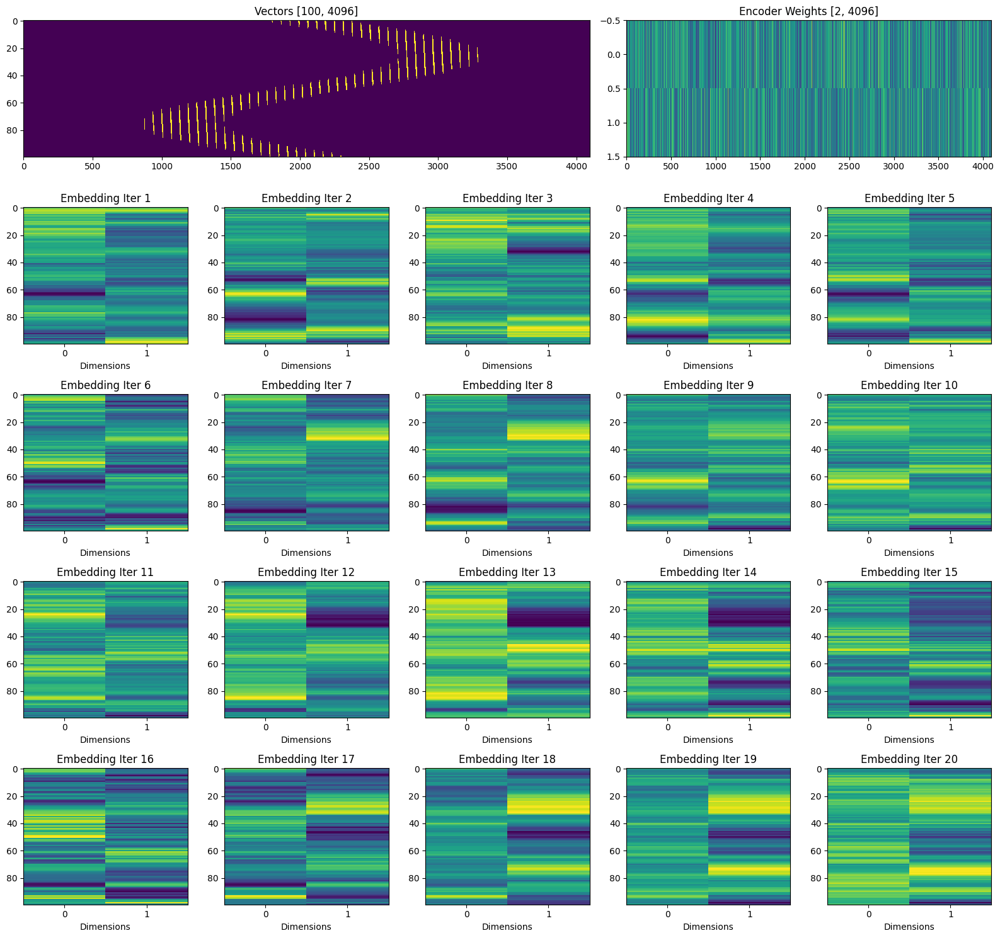

Bias: [ 0.00941124 -0.00242332]


In [8]:
import matplotlib.pyplot as plt
import math

n = len(embeddings)
rows = math.ceil(n / 5)

fig = plt.figure(figsize=(16, 3 * (rows + 1)))
gs = fig.add_gridspec(rows + 1, 5)

# Top row
ax1 = fig.add_subplot(gs[0, 0:3])
ax2 = fig.add_subplot(gs[0, 3:5])

ax1.imshow(x.numpy(), aspect="auto", interpolation="nearest")
ax1.set_title("Vectors [100, 4096]")

ax2.imshow(encoder.weight.detach().numpy(), aspect="auto", interpolation="nearest")
ax2.set_title("Encoder Weights [2, 4096]")

# Embeddings: 5 per row
for i, z in enumerate(embeddings):
    row = i // 5 + 1
    col = i % 5

    ax = fig.add_subplot(gs[row, col])
    ax.imshow(z.numpy(), aspect="auto", interpolation="nearest")
    ax.set_title(f"Embedding Iter {i+1}")
    ax.set_xticks([0, 1])
    ax.set_xlabel("Dimensions")

plt.tight_layout()
plt.show()

print("Bias:", encoder.bias.detach().numpy())

* Vectors - Contain the pixel values of each video frame, not the movement explicitly.
* Encoder Weights - Learn how to transform pixel values into embeddings. Biases are also trainable parameters.
* Embeddings - Change during training. The goal is to capture useful information about the video, but our current loss only encourages consecutive frames to have similar embeddings, potentially causing collapse.

### Euclidean Distance & MSE

* **Euclidean Distance** - Measures how far apart two embeddings are.

$$
d(z_1,z_2) = \left(\sum_{j=1}^{D}(z_{1j}-z_{2j})^2\right)^{1/2}
$$

* **Squared Euclidean Distance** - Sum of squared differences between coordinates.

$$
d^2(z_1,z_2) = \sum_{j=1}^{D}(z_{1j}-z_{2j})^2
$$

* **MSE (Mean Squared Error)** - Squared Euclidean distance divided by the number of dimensions.

$$
MSE(z_1,z_2) = \frac{1}{D}\sum_{j=1}^{D}(z_{1j}-z_{2j})^2
$$

* **Invariance Loss** - Minimizes differences between embeddings of different views of the same video.

$$
L_{inv} = \frac{1}{V}\sum_{v=1}^{V}\|z_0-z_v\|_2^2
$$



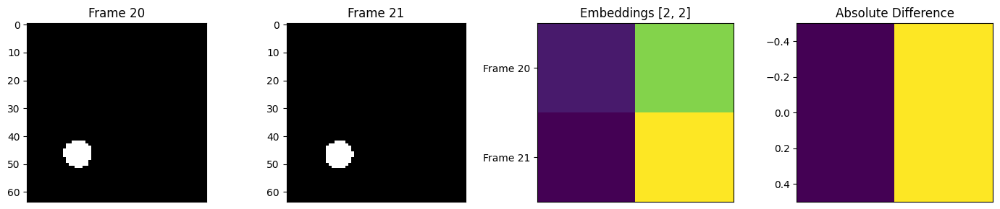

Euclidean Distance: 0.012696
Squared Euclidean Distance: 0.000161
MSE: 0.000081


In [9]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3))

# Original frames
axs[0].imshow(frames[20], cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Frame 20")

axs[1].imshow(frames[21], cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Frame 21")

# Embeddings and their difference
z1 = embeddings[-1][20]
z2 = embeddings[-1][21]

axs[2].imshow(torch.stack([z1, z2]).numpy(), aspect="auto")
axs[2].set_title("Embeddings [2, 2]")
axs[2].set_yticks([0, 1], ["Frame 20", "Frame 21"])

axs[3].imshow((z1 - z2).abs().numpy().reshape(1, -1), aspect="auto")
axs[3].set_title("Absolute Difference")

for ax in axs:
    ax.set_xticks([])

plt.tight_layout()
plt.show()

# Calculate distances
euclidean = torch.dist(z1, z2)
squared = ((z1 - z2) ** 2).sum()
mse = ((z1 - z2) ** 2).mean()

print(f"Euclidean Distance: {euclidean.item():.6f}")
print(f"Squared Euclidean Distance: {squared.item():.6f}")
print(f"MSE: {mse.item():.6f}")

* Embeddings [2,2]
  * 2 rows - Frame 20 and Frame 21
  * 2 columns - Each frame has an embedding containing 2 numbers
  * Colors - Show the values of those numbers

* Absolute Difference
  * Subtracts the two embeddings and takes the absolute value of each difference
  * Example: [0.5, 0.2] and [0.3, 0.1] $\rightarrow$ [0.2, 0.1]

So, Embeddings [2,2] shows 2 vectors, and Absolute Difference shows how they differ.

### Variance & Covariance

* **Variance** - Measures how much values spread across 100 embeddings within a single embedding dimension.

$$
Var(z_j) = \frac{1}{n}\sum_{i=1}^{n}(z_{ij}-\mu_j)^2
$$

* **Covariance** - Measures how two embedding dimensions change together across 100 embeddings.

$$
Cov(z_1,z_2) = \frac{1}{n}\sum_{i=1}^{n}(z_{i1}-\mu_1)(z_{i2}-\mu_2)
$$

* **n** - Number of embeddings (100, one per video frame).
* **i** - Embedding index (frame index).
* **j** - Embedding dimension index (1 or 2).
* **z_ij** - Value of dimension j in embedding i.
* **μ_j** - Mean value of dimension j across all 100 embeddings.
* **Representation Collapse** - All embeddings become identical, so variance across embeddings approaches zero in every dimension.

* Variance - Multiplies deviations within the same embedding dimension, so it cannot be negative
* Covariance -  multiplies deviations of two different embedding dimensions, so it can be positive or negative.

Iteration  1 | Variance: [0.00510881 0.00334822] | Mean: 0.004229 | Covariance: 0.000263
Iteration  2 | Variance: [0.02843658 0.01723164] | Mean: 0.022834 | Covariance: 0.000051
Iteration  3 | Variance: [0.00319766 0.00553569] | Mean: 0.004367 | Covariance: 0.000272
Iteration  4 | Variance: [0.00926972 0.00531481] | Mean: 0.007292 | Covariance: -0.001053
Iteration  5 | Variance: [0.0108317  0.00599357] | Mean: 0.008413 | Covariance: -0.001023
Iteration  6 | Variance: [0.00521253 0.00443752] | Mean: 0.004825 | Covariance: -0.000631
Iteration  7 | Variance: [0.00298364 0.00331062] | Mean: 0.003147 | Covariance: -0.000371
Iteration  8 | Variance: [0.0035806  0.00338697] | Mean: 0.003484 | Covariance: -0.000069
Iteration  9 | Variance: [0.00348808 0.00327457] | Mean: 0.003381 | Covariance: 0.000264
Iteration 10 | Variance: [0.00251418 0.00241834] | Mean: 0.002466 | Covariance: 0.000158
Iteration 11 | Variance: [0.00197265 0.00200969] | Mean: 0.001991 | Covariance: -0.000412
Iteration 12 | 

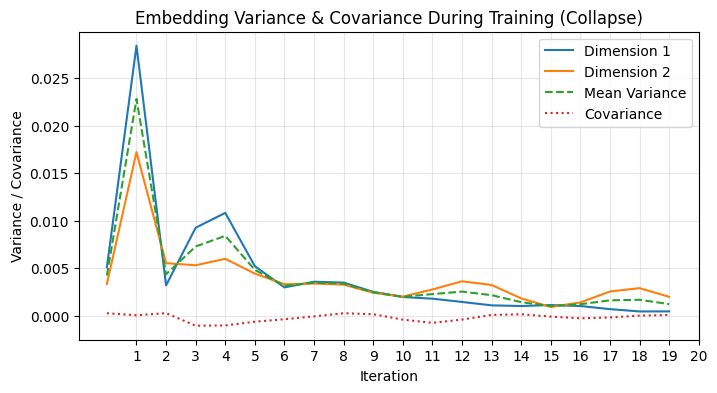

In [10]:
variances = []
covariances = []

# Measure variance and covariance across training iterations
for i, z in enumerate(embeddings):
    variance = z.var(dim=0, unbiased=False)
    covariance = torch.cov(z.T, correction=0)[0, 1]

    variances.append(variance.numpy())
    covariances.append(covariance.item())

    print(f"Iteration {i+1:2} | Variance: {variance.numpy()} | "
          f"Mean: {variance.mean():.6f} | Covariance: {covariance:.6f}")

variances = np.array(variances)
covariances = np.array(covariances)

# Plot variance and covariance over training iterations
plt.figure(figsize=(8, 4))
plt.plot(variances[:, 0], label="Dimension 1")
plt.plot(variances[:, 1], label="Dimension 2")
plt.plot(variances.mean(axis=1), label="Mean Variance", linestyle="--")
plt.plot(covariances, label="Covariance", linestyle=":")

plt.xlabel("Iteration")
plt.ylabel("Variance / Covariance")
plt.title("Embedding Variance & Covariance During Training (Collapse)")
plt.legend()
plt.xticks(np.arange(1, len(embeddings) + 1))
plt.grid(alpha=0.3)
plt.show()

* As training progresses, the embeddings become increasingly similar.
* The decreasing variance shows that the model is gradually losing its ability to distinguish between different video frames.
* **Representation collapse** happens when the model produces nearly identical embeddings for different inputs, losing useful information about them.
* SIGReg is designed to prevent this collapse. We'll explore how it works in a later section.

### Gaussian Distribution

* **Gaussian Distribution** - A bell-shaped distribution where most values are near the mean.
* **Mean (μ)** - Center of the distribution.
* **Standard Deviation (σ)** - How spread out the values are.
* **Standard Normal Distribution** - A Gaussian with mean 0 and variance 1.

$$
p(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

* **Connection to LeVJEPA** - SIGReg pushes embedding projections toward a standard normal distribution N(0,1).
* **Representation Collapse** - Embeddings become nearly identical, so their variance approaches 0.
* **How SIGReg Prevents Collapse** - As we saw earlier, collapse pushes variance and standard deviation toward 0. SIGReg pushes the standard deviation of embedding projections toward 1. Since $0 \neq 1$, SIGReg prevents all embeddings from becoming identical.
* **SIGReg Preview** - We'll visualize this difference now and explain how SIGReg works mathematically in a later section.
* **Next** - We'll explain the actual mathematics behind SIGReg in greater detail in a later section.

$$
L_{SIGReg} = \frac{1}{M}\sum_{m=1}^{M}\int \Big|\frac{1}{n}\sum_{i=1}^{n}e^{ita_m^Tz_i}-e^{-t^2/2}\Big|^2e^{-t^2/2}dt
$$

Embedding  1 | SIGReg loss: 0.002914
Embedding  2 | SIGReg loss: 0.002514
Embedding  3 | SIGReg loss: 0.002322
Embedding  4 | SIGReg loss: 0.002382
Embedding  5 | SIGReg loss: 0.002249
Embedding  6 | SIGReg loss: 0.002307
Embedding  7 | SIGReg loss: 0.003186
Embedding  8 | SIGReg loss: 0.002939
Embedding  9 | SIGReg loss: 0.002947
Embedding 10 | SIGReg loss: 0.003560
Embedding 11 | SIGReg loss: 0.003341
Embedding 12 | SIGReg loss: 0.006129
Embedding 13 | SIGReg loss: 0.003869
Embedding 14 | SIGReg loss: 0.003145
Embedding 15 | SIGReg loss: 0.003596
Embedding 16 | SIGReg loss: 0.002368
Embedding 17 | SIGReg loss: 0.002858
Embedding 18 | SIGReg loss: 0.004194
Embedding 19 | SIGReg loss: 0.003537
Embedding 20 | SIGReg loss: 0.003196


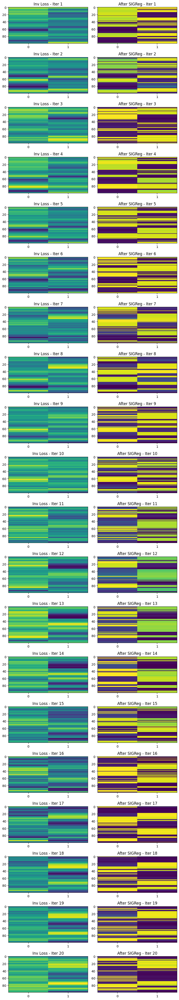

In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Approximate SIGReg loss on a batch of embeddings z: [n, d]
def sigreg_loss(z, M=32, T=128, t_max=4.0):
    device = z.device
    d = z.shape[1]

    # Random projection directions
    a = torch.randn(M, d, device=device)
    a = a / (a.norm(dim=1, keepdim=True) + 1e-8)

    # Integration grid
    t = torch.linspace(-t_max, t_max, T, device=device)
    target = torch.exp(-0.5 * t**2)  # characteristic function of N(0,1)

    loss = 0.0
    for m in range(M):
        proj = z @ a[m]                               # [n]
        phi_emp = torch.exp(1j * t[:, None] * proj[None, :]).mean(dim=1)  # [T]
        diff_sq = (phi_emp.real - target) ** 2 + phi_emp.imag ** 2
        loss = loss + (diff_sq * target).mean()

    return loss / M


# Apply SIGReg directly to saved embeddings for visualization
sigreg_embeddings = []

for i, z_init in enumerate(embeddings):
    z_var = z_init.clone().detach().requires_grad_(True)
    optimizer = torch.optim.Adam([z_var], lr=1e-2)

    for step in range(100):
        loss = sigreg_loss(z_var)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    sigreg_embeddings.append(z_var.detach().clone())
    print(f"Embedding {i+1:2} | SIGReg loss: {loss.item():.6f}")


# Plot: left column = inv loss embeddings, right column = after SIGReg
n = len(embeddings)
fig, axs = plt.subplots(n, 2, figsize=(8, 2.2 * n), squeeze=False)

for i in range(n):
    axs[i, 0].imshow(embeddings[i].numpy(), aspect="auto", interpolation="nearest")
    axs[i, 0].set_xticks([0, 1])
    axs[i, 0].set_title(f"Inv Loss - Iter {i+1}")

    axs[i, 1].imshow(sigreg_embeddings[i].numpy(), aspect="auto", interpolation="nearest")
    axs[i, 1].set_xticks([0, 1])
    axs[i, 1].set_title(f"After SIGReg - Iter {i+1}")

plt.tight_layout()
plt.show()

* **Current Visualization** - We use `flatten()` to combine all 100 embeddings `[100, 2]` into 200 values and visualize their distribution.
* **Limitation** - This helps us see how the embeddings spread out, but it is not how SIGReg measures their distribution.
* **Actual SIGReg** - Uses scalar projections (`z @ a`) to convert 100 embeddings into 100 values along a chosen direction.
* **Next Section** - We'll explain vector projection and visualize how SIGReg uses it.

Iteration  1 | L_inv Std: 0.0666 | SIGReg Std: 0.2540
Iteration  2 | L_inv Std: 0.1511 | SIGReg Std: 0.4263
Iteration  3 | L_inv Std: 0.0671 | SIGReg Std: 0.6068
Iteration  4 | L_inv Std: 0.0872 | SIGReg Std: 0.7863
Iteration  5 | L_inv Std: 0.0931 | SIGReg Std: 0.9310
Iteration  6 | L_inv Std: 0.0700 | SIGReg Std: 1.0256
Iteration  7 | L_inv Std: 0.0561 | SIGReg Std: 1.0728
Iteration  8 | L_inv Std: 0.0590 | SIGReg Std: 1.0743
Iteration  9 | L_inv Std: 0.0582 | SIGReg Std: 1.0463
Iteration 10 | L_inv Std: 0.0504 | SIGReg Std: 1.0040
Iteration 11 | L_inv Std: 0.0476 | SIGReg Std: 0.9551
Iteration 12 | L_inv Std: 0.0530 | SIGReg Std: 0.9075
Iteration 13 | L_inv Std: 0.0561 | SIGReg Std: 0.8697
Iteration 14 | L_inv Std: 0.0512 | SIGReg Std: 0.8458
Iteration 15 | L_inv Std: 0.0407 | SIGReg Std: 0.8346
Iteration 16 | L_inv Std: 0.0329 | SIGReg Std: 0.8352
Iteration 17 | L_inv Std: 0.0349 | SIGReg Std: 0.8458
Iteration 18 | L_inv Std: 0.0403 | SIGReg Std: 0.8659
Iteration 19 | L_inv Std: 0.

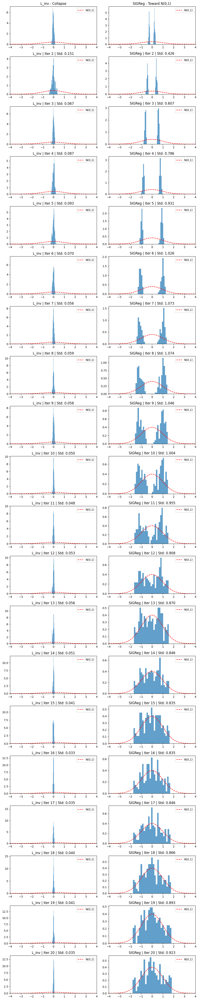

In [12]:
# Left: saved L_inv embeddings
# Right: sequential SIGReg updates starting from the first embedding

z_sig = embeddings[0].detach().clone().requires_grad_(True)
optimizer = torch.optim.Adam([z_sig], lr=0.2)

t = np.linspace(-4, 4, 500)
gaussian = np.exp(-t**2 / 2) / np.sqrt(2 * np.pi)

fig, axs = plt.subplots(len(embeddings), 2,
                        figsize=(10, 2.5 * len(embeddings)),
                        squeeze=False)

for i, z_inv in enumerate(embeddings):

    # One SIGReg update per iteration
    loss = sigreg_loss(z_sig)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Compare embedding distributions
    for ax, z, title in [
        (axs[i, 0], z_inv.detach(), "L_inv"),
        (axs[i, 1], z_sig.detach(), "SIGReg")
    ]:
        values = z.numpy().flatten()
        ax.hist(values, bins=25, density=True, alpha=0.7)
        ax.plot(t, gaussian, "r--", label="N(0,1)")
        ax.set_xlim(-4, 4)
        ax.set_title(f"{title} | Iter {i+1} | Std: {values.std():.3f}")
        ax.legend()

    print(f"Iteration {i+1:2} | "
          f"L_inv Std: {z_inv.std(unbiased=False):.4f} | "
          f"SIGReg Std: {z_sig.std(unbiased=False):.4f}")

axs[0, 0].set_title("L_inv - Collapse")
axs[0, 1].set_title("SIGReg - Toward N(0,1)")

plt.tight_layout()
plt.show()

* **L_inv** - Embeddings become increasingly similar, and their standard deviation approaches 0. The model gradually loses information about the video.
* **SIGReg** - Standard deviation moves toward 1, meaning the embeddings spread out again instead of collapsing.
* **Two Peaks** - Our embeddings form two groups because SIGReg is still optimizing their distribution. They haven't reached a Gaussian shape yet.
* **Why This Is Good** - SIGReg prevents the encoder from producing identical embeddings for every frame, allowing it to preserve differences between them.
* **Conclusion** - SIGReg prevents collapse, but standard deviation approaching 1 doesn't automatically mean the distribution is Gaussian.

### Vector Projection

* **Embedding Coordinates** - Our matrix `[100, 2]` contains 100 embeddings, each represented by two numbers `[x, y]`. We treat each embedding as a point in 2D space and draw a vector from the origin `[0, 0]` to that point.

* **Random Direction** - We randomly generate another vector `[random_x, random_y]`, starting at `[0, 0]`, and normalize its length to 1. This vector defines an axis onto which we project our embeddings. We use the same direction for all 100 embeddings in one projection. SIGReg uses many randomly generated directions.

* **Vector Projection** - We project each embedding onto our random direction axis. Imagine dropping a perpendicular line from each embedding point onto that axis. The point where the line touches the axis is its projection, still represented by two coordinates `[x, y]`.

* **Scalar Projection** - Instead of keeping the two coordinates `[x, y]` of the projected point, we represent its position along the random direction axis with just one number. This number tells us how far the projected point is from `[0, 0]`, including whether it lies in the positive or negative direction.

* **SIGReg** - We now have 100 scalar projections, one for each embedding. SIGReg compares their distribution with the standard normal distribution $N(0,1)$. The greater the difference between these distributions, the higher the SIGReg loss. Backpropagation updates the encoder weights to reduce this difference.

Iteration  1 | SIGReg Loss: 0.049906
Iteration  2 | SIGReg Loss: 0.039400
Iteration  3 | SIGReg Loss: 0.024072
Iteration  4 | SIGReg Loss: 0.010566
Iteration  5 | SIGReg Loss: 0.004365
Iteration  6 | SIGReg Loss: 0.004883
Iteration  7 | SIGReg Loss: 0.007856
Iteration  8 | SIGReg Loss: 0.014589
Iteration  9 | SIGReg Loss: 0.011180
Iteration 10 | SIGReg Loss: 0.008823
Iteration 11 | SIGReg Loss: 0.006732
Iteration 12 | SIGReg Loss: 0.003486
Iteration 13 | SIGReg Loss: 0.002889
Iteration 14 | SIGReg Loss: 0.003224
Iteration 15 | SIGReg Loss: 0.003538
Iteration 16 | SIGReg Loss: 0.004182
Iteration 17 | SIGReg Loss: 0.004731
Iteration 18 | SIGReg Loss: 0.003610
Iteration 19 | SIGReg Loss: 0.003274
Iteration 20 | SIGReg Loss: 0.002545


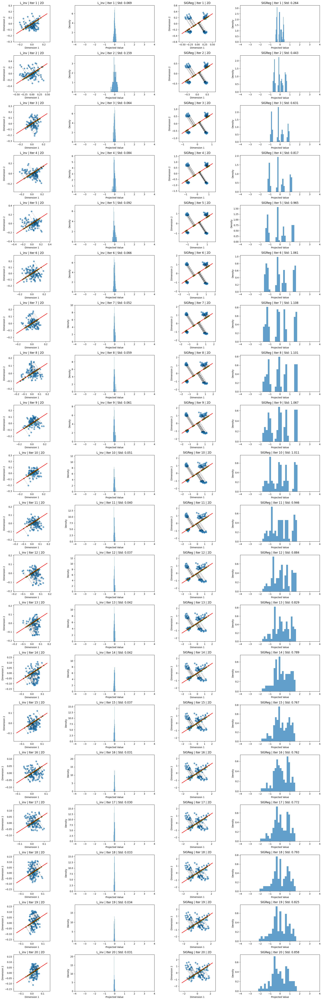

In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Fixed projection direction for both experiments
a = np.random.randn(2)
a = a / np.linalg.norm(a)

# Sequential SIGReg updates starting from the first saved embedding
z_sig = embeddings[0].detach().clone().requires_grad_(True)
optimizer = torch.optim.Adam([z_sig], lr=0.2)

sig_embeddings = []

for i in range(len(embeddings)):
    loss = sigreg_loss(z_sig)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    sig_embeddings.append(z_sig.detach().clone())

    print(f"Iteration {i+1:2} | SIGReg Loss: {loss.item():.6f}")

# Plot 4 columns per iteration
fig, axs = plt.subplots(
    len(embeddings), 4,
    figsize=(20, 3 * len(embeddings)),
    squeeze=False
)

for i in range(len(embeddings)):
    for col, (z_tensor, name) in enumerate([
        (embeddings[i], "L_inv"),
        (sig_embeddings[i], "SIGReg")
    ]):
        z = z_tensor.detach().cpu().numpy()

        # Scalar and vector projections
        p = z @ a
        projected = np.outer(p, a)

        # 2D embeddings and projections
        ax = axs[i, col * 2]

        ax.scatter(z[:, 0], z[:, 1], alpha=0.6, label="Embeddings")
        ax.scatter(projected[:, 0], projected[:, 1],
                   color="green", s=15, label="Projections")

        for point, proj in zip(z, projected):
            ax.plot(
                [point[0], proj[0]],
                [point[1], proj[1]],
                "k--", alpha=0.2
            )

        # Full projection axis through [0, 0]
        limit = max(np.abs(z).max(), np.abs(projected).max(), 0.01) * 1.5
        axis_points = np.array([-limit * a, limit * a])

        ax.plot(axis_points[:, 0], axis_points[:, 1],
                color="red", linewidth=2, label="Projection Axis")

        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit, limit)
        ax.set_aspect("equal")
        ax.set_title(f"{name} | Iter {i+1} | 2D")
        ax.set_xlabel("Dimension 1")
        ax.set_ylabel("Dimension 2")

        # Scalar projection distribution
        ax = axs[i, col * 2 + 1]
        ax.hist(p, bins=20, density=True, alpha=0.7)
        ax.set_xlim(-4, 4)
        ax.set_title(f"{name} | Iter {i+1} | Std: {p.std():.3f}")
        ax.set_xlabel("Projected Value")
        ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

* **L_inv** - Embeddings gradually collapse into a single point, and their standard deviation approaches 0.
* **SIGReg** - Embeddings spread out, and their projected standard deviation approaches 1.
* **Four Blobs** - Caused by directly optimizing embeddings with a high learning rate, not by SIGReg itself.
* **Conclusion** - SIGReg prevents collapse, although the distribution is not yet perfectly Gaussian.

### Complex Numbers & Probability Distributions


Source: https://www.3blue1brown.com/lessons/eulers-formula-dynamically/?utm_source=chatgpt.com$0

#### $e^t$

* $e^t$ is a function which has property that a function is equal to its own derivative, with added condition that inputting 0 returns 1.

$$ \frac{d}{dt}e^t = e^t $$
$$ e^0 = 1 $$

If we assume that $e^t$ defines the position of an object at time $t$:

$$
\underbrace{x(t) = e^t}_{\text{Position}}
$$

And we remember that the first derivative of position with respect to time is velocity:

$$
v(t) = \frac{dx}{dt} = e^t
$$

At every moment, velocity is numerically equal to the current position (distance from 0). This means our speed increases proportionally to the distance from 0.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

def animate(k, t_max=2, frames=100):
    t = np.linspace(0, t_max, frames)
    x = np.exp(abs(k) * t)       # blue: always from 0 to the right
    v = k * x                    # green: velocity

    lim = 1.1 * np.max(np.abs(np.concatenate([x, x + v, v])))

    fig, ax = plt.subplots(figsize=(9, 3))
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-0.7, 0.7)
    ax.set_yticks([])
    ax.set_xlabel("Position")
    ax.set_title(f"k = {k}")
    ax.axhline(0, color="gray")
    ax.axvline(0, color="black", linewidth=1)

    position = ax.quiver(0, 0, x[0], 0, color="blue",
                         angles="xy", scale_units="xy", scale=1, label="position")
    velocity = ax.quiver(0, 0, v[0], 0, color="green",
                         angles="xy", scale_units="xy", scale=1, label="velocity")
    ax.legend(loc="lower right")

    label = ax.text(0.5, 0.85, "", transform=ax.transAxes, ha="center")

    def update(i):
        position.set_UVC(x[i], 0)

        if k < 0:
            velocity.set_offsets([[0, 0]])      # green starts at 0, goes left
        else:
            velocity.set_offsets([[x[i], 0]])   # green starts at tip of blue
        velocity.set_UVC(v[i], 0)

        label.set_text(f"t = {t[i]:.2f} | Position = {x[i]:.3f} | Velocity = {v[i]:.3f}")
        return position, velocity, label

    anim = FuncAnimation(fig, update, frames=frames, interval=50, blit=True)
    plt.tight_layout()
    plt.close(fig)
    display(HTML(anim.to_jshtml()))

animate(1)

If we define position as $e^{2t}$ then due to chain rule our velocity is 2 times faster than position we have.

$$ \frac{d}{dt} e^{2t} = 2\cdot e^{2t} $$

In [15]:
animate(2)

If we define position as $e^{-0.5t}$ then due to chain rule our velocity is -0.5 times faster than position we have, meaning we slow down by half and go opposite direction due to negative value.

$$ \frac{d}{dt}e^{-0.5t} = -0.5\cdot e^{-0.5t} $$

In [16]:
animate(-0.5)

#### Imaginary Number

Complex number is an expression with real and imaginary number:

$$ \text{Complex number } \rightarrow 3+2i $$
$$ \text{Imaginary number } \rightarrow 2i $$
$$ \text{Real number } \rightarrow 3 $$

Where:

$$ i^2 = -1 $$

#### Multiplying by i = Rotation by 90°

Multiplying a complex number by $i$ rotates it by 90° around $0$:

$$1 \xrightarrow{\cdot i} i \xrightarrow{\cdot i} -1 \xrightarrow{\cdot i} -i \xrightarrow{\cdot i} 1$$

Four rotations by 90° make a full circle. That's why $i^2 = -1$: two rotations by 90° = 180° = pointing the opposite way.

#### $e^{it}$

Same rule as before — the function equals its own derivative times the constant in the exponent:

$$\frac{d}{dt}e^{it} = i \cdot e^{it}$$

- **Velocity = i · position** — velocity is the position rotated by 90°.
- **Always perpendicular** — velocity never points toward or away from 0, so the distance from 0 never changes. We move on a circle of radius 1.
- **Speed = 1** — after time $t$ we travel an arc of length $t$, so $t$ is the angle.

$$e^{it} = \cos t + i \sin t$$

#### $e^{i\pi} = -1$

After time $\pi$ we travel half of the circle (full circle = $2\pi$), starting from $1$ — we land at $-1$.

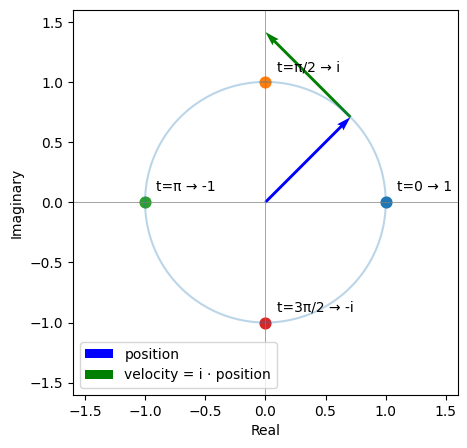

(-1+1.2246467991473532e-16j)


In [17]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 2 * np.pi, 200)
z = np.exp(1j * t)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(z.real, z.imag, alpha=0.3)

# Key points on the circle
for tk, label in [(0, "t=0 → 1"), (np.pi / 2, "t=π/2 → i"),
                  (np.pi, "t=π → -1"), (3 * np.pi / 2, "t=3π/2 → -i")]:
    p = np.exp(1j * tk)
    ax.scatter(p.real, p.imag, s=60)
    ax.annotate(label, (p.real, p.imag), textcoords="offset points", xytext=(8, 8))

# Position and velocity at t = π/4
p = np.exp(1j * np.pi / 4)
v = 1j * p
ax.quiver(0, 0, p.real, p.imag, angles="xy", scale_units="xy", scale=1,
          color="blue", label="position")
ax.quiver(p.real, p.imag, v.real, v.imag, angles="xy", scale_units="xy", scale=1,
          color="green", label="velocity = i · position")

ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_aspect("equal")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.set_xlabel("Real")
ax.set_ylabel("Imaginary")
ax.legend(loc="lower left")
plt.show()

print(np.exp(1j * np.pi))  # -1 (+ tiny numerical error in imaginary part)

### Characteristic Functions

* **Characteristic Function** - Converts a probability distribution into a mathematical function using a fixed formula. No training or learning is involved.
* **Why?** - Instead of comparing histograms, we compare two mathematical functions.
* **Empirical Characteristic Function** - Uses our 100 scalar projections to calculate this function.
* **SIGReg** - Compares the function calculated from our embeddings with the known characteristic function of N(0,1). The difference becomes the loss.

$$
\phi(t) = E[e^{itX}]
$$

For our 100 scalar projections:

$$
\phi(t) = \frac{1}{100}\sum_{j=1}^{100}e^{itp_j}
$$

* **X** - Random variable representing scalar projections.
* **p_j** - One of our 100 scalar projections.
* **t** - A number we vary to obtain different values of the function.
* **i** - Imaginary unit, where $i^2=-1$.
* **E** - Expected value (average).
* **Result** - We transform 100 scalar projections into a function that describes their distribution without training another model.

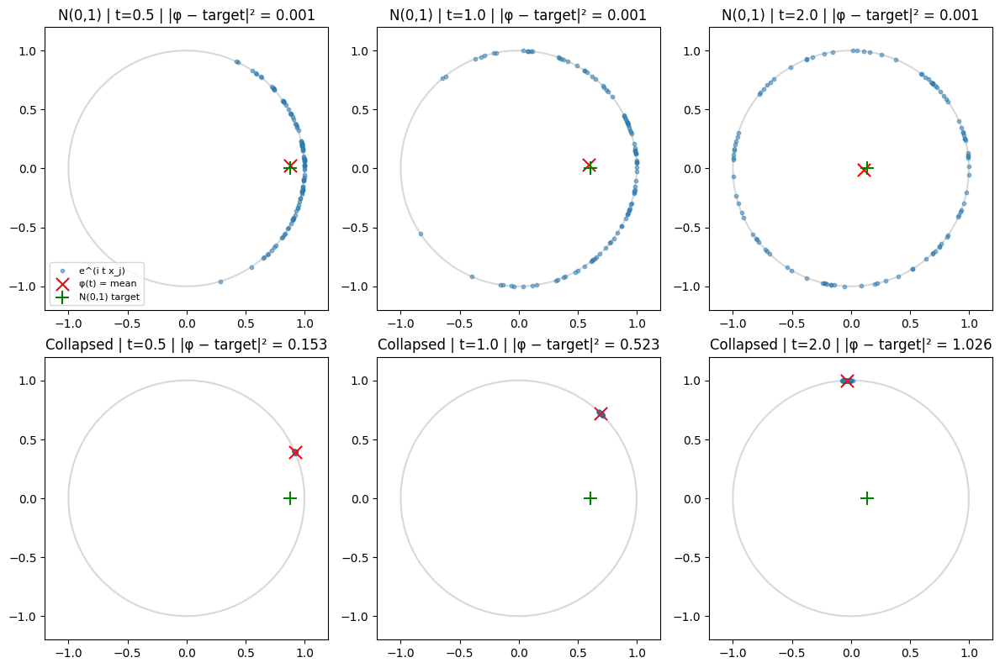

In [18]:
np.random.seed(0)
samples = {
    "N(0,1)": np.random.randn(100),
    "Collapsed": 0.8 + 0.01 * np.random.randn(100),
}
ts = [0.5, 1.0, 2.0]
circle = np.exp(1j * np.linspace(0, 2 * np.pi, 200))

fig, axs = plt.subplots(2, len(ts), figsize=(12, 8))

for r, (name, x) in enumerate(samples.items()):
    for c, t in enumerate(ts):
        ax = axs[r, c]
        pts = np.exp(1j * t * x)        # each sample -> point on the circle
        phi = pts.mean()                # center of mass
        target = np.exp(-t**2 / 2)      # CF of N(0,1)

        ax.plot(circle.real, circle.imag, color="gray", alpha=0.3)
        ax.scatter(pts.real, pts.imag, s=10, alpha=0.5, label="e^(i t x_j)")
        ax.scatter(phi.real, phi.imag, s=120, marker="x", color="red", label="φ(t) = mean")
        ax.scatter(target, 0, s=120, marker="+", color="green", label="N(0,1) target")

        ax.set_aspect("equal")
        ax.set_xlim(-1.2, 1.2)
        ax.set_ylim(-1.2, 1.2)
        ax.set_title(f"{name} | t={t} | |φ − target|² = {abs(phi - target)**2:.3f}")

axs[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()


- **Each sample** $x_j$ becomes a point $e^{itx_j}$ on the unit circle at angle $t \cdot x_j$.
- **$\phi(t)$** (red ×) is the mean of these points. **Target** (green +) is $e^{-t^2/2}$, the characteristic function of N(0,1).
- **N(0,1)** — points spread around the circle as $t$ grows, the mean moves toward the center and matches the target. $|\phi - \text{target}|^2 \approx 0.001$ for every $t$.
- **Collapsed** — all samples ≈ 0.8, so all points land in one spot that only rotates as $t$ grows. The mean stays on the circle and never reaches the target inside it. The loss grows with $t$: 0.153 → 0.523 → 1.026.

**Why a characteristic function instead of something simpler**
- **RMSE** — needs pairs of values, but distributions have no pairs. We compare the shape of a cloud, not individual points.
- **Histogram** — binning is a step function, so the gradient is 0 or undefined. The encoder gets no signal.
- **Mean + std** (VICReg) — prevents collapse, but doesn't control the shape (two clusters with std = 1 pass).
- **Characteristic function** — differentiable (a small change in $x$ moves the point slightly along the circle), controls the full shape, stable ($|e^{itx}| = 1$, so outliers can't explode), cheap (a mean over the batch).

**SIGReg**
- Projects embeddings onto many random directions, computes $\phi(t)$ of the projections for many $t$, and penalizes the distance to $e^{-t^2/2}$.
- Gradients push the encoder from the bottom row toward the top row — embeddings spread out instead of collapsing.

# Training the Encoder with L_inv + SIGReg

So far SIGReg was applied **directly to embeddings**. LeVJEPA applies it **through the encoder** — gradients update the encoder weights, not the embeddings.

$$L = L_{inv} + \lambda \cdot L_{SIGReg}$$

We train two identical encoders:
- **L_inv only** — expected to collapse.
- **L_inv + SIGReg** — expected to keep frames apart while consecutive frames stay close.

If the embeddings colored by frame form a continuous path, the encoder preserved the ball's trajectory.

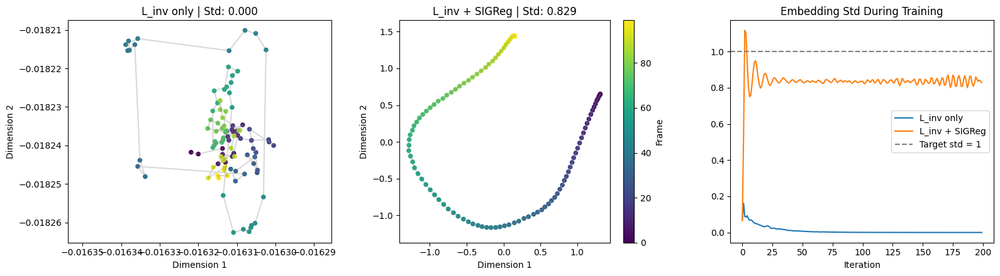

L_inv only     | inv: 0.0000 | std: 0.000
L_inv + SIGReg | inv: 0.0022 | sigreg: 0.0015 | std: 0.828


In [19]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

x = torch.tensor(frames).flatten(1)  # [100, 4096]
torch.manual_seed(0)

def train(use_sigreg, lam=1.0, steps=200, lr=1e-2):
    encoder = nn.Linear(4096, 2)
    opt = torch.optim.Adam(encoder.parameters(), lr=lr)
    history = []

    for i in range(steps):
        z = encoder(x)
        inv = ((z[1:] - z[:-1]) ** 2).mean()
        reg = sigreg_loss(z) if use_sigreg else torch.tensor(0.0)
        loss = inv + lam * reg

        opt.zero_grad()
        loss.backward()
        opt.step()

        history.append([inv.item(), reg.item(), z.std(0).mean().item()])

    return encoder(x).detach().numpy(), np.array(history)

z_inv, h_inv = train(use_sigreg=False)
z_sig, h_sig = train(use_sigreg=True)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

# Embeddings colored by frame
for ax, z, title in [(axs[0], z_inv, "L_inv only"), (axs[1], z_sig, "L_inv + SIGReg")]:
    sc = ax.scatter(z[:, 0], z[:, 1], c=np.arange(len(z)), cmap="viridis", s=20)
    ax.plot(z[:, 0], z[:, 1], color="gray", alpha=0.3)
    ax.set_title(f"{title} | Std: {z.std(0).mean():.3f}")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.set_aspect("equal", adjustable="datalim")
fig.colorbar(sc, ax=axs[1], label="Frame")

# Std during training
axs[2].plot(h_inv[:, 2], label="L_inv only")
axs[2].plot(h_sig[:, 2], label="L_inv + SIGReg")
axs[2].axhline(1, color="gray", linestyle="--", label="Target std = 1")
axs[2].set_title("Embedding Std During Training")
axs[2].set_xlabel("Iteration")
axs[2].legend()

plt.tight_layout()
plt.show()

print(f"L_inv only     | inv: {h_inv[-1, 0]:.4f} | std: {h_inv[-1, 2]:.3f}")
print(f"L_inv + SIGReg | inv: {h_sig[-1, 0]:.4f} | sigreg: {h_sig[-1, 1]:.4f} | std: {h_sig[-1, 2]:.3f}")


- **L_inv only** — collapse. All 100 embeddings sit in a tiny region (axis range ~0.00005), std = 0.000, and frame order is lost (colors are mixed).
- **L_inv + SIGReg** — no collapse. Std ≈ 0.83, and embeddings form a smooth, ordered path from frame 0 to frame 99. The encoder preserved the ball's trajectory, learned without labels.
- **Std < 1** — L_inv pulls consecutive frames together while SIGReg pushes the spread toward 1. The equilibrium between the two lands at ~0.83; `lam` controls this balance.
- **Oscillations** in the std curve come from the learning rate, not from SIGReg.

**Conclusion** — L_inv alone learns nothing. Adding SIGReg is enough to prevent collapse and recover the structure of the video.